# Baseline check — sub-pilot003 / ses-prime / run 103

Does pre-stimulus noise predict the online N45 dipole? For every single-pulse intervention trial the
online system successfully post-processed, this notebook regenerates the pre-stimulus
**baseline-correction window** (`cfg.baseline`, [-25, -15] ms) from the trial's saved raw buffer, fits
a free-orientation dipole to it the same way `DipoleFitter.fit_trial` would, and compares that
amplitude against `tep_amplitude_raw` — the online N45 dipole amplitude already stored in
`trials_intervention.csv` for the same trial.

Companion to `PRIME_online_performance.ipynb` and `claude/online_TEP_replay.md`: it reuses the same
`Preprocessor.from_bundle()` / `DipoleFitter._fitting_info` restoration and session-identification
convention those establish, but is otherwise self-contained — nothing below depends on the other
notebook having been run first.

## 1 · Session setup and identification

The session is identified by three strings below (`SUBJECT_ID`, `SESSION_ID`, `RUN_ID`), which are
joined onto a `Loop` root folder to find the NeuroSimo output directory:
`<LOOP_ROOT>/BIDS/sub-<SUBJECT_ID>/<SESSION_ID>/<RUN_ID>/prime`. To point this notebook at a
different session, edit the three strings and re-run — nothing below refers to Pilot003 by name.

`LOOP_ROOT` is resolved the same way as `PRIME_online_performance.ipynb`: the `LOOP_ROOT`
environment variable if set, else the lab Windows path `D:\Linus\Loop`, else `~/Desktop/Loop` (Mac),
else the first parent of the current working directory that contains both a `BIDS/` and a `prime/`
folder.

In [1]:
from __future__ import annotations

import os, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import mne

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 100, "figure.figsize": (10, 3.4),
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

# Same colours PRIME_online_performance.ipynb uses for these conditions.
COLOR_PREDETERMINED = "#5b8ff9"   # blue
COLOR_PRIME_SINGLE   = "#e8684a"  # orange

print(f"numpy {np.__version__}  pandas {pd.__version__}  mne {mne.__version__}")

numpy 2.3.2  pandas 2.3.1  mne 1.10.0


In [2]:
# ---------------------------------------------------------------- session identification
SUBJECT_ID = "pilot003"     # BIDS subject label, without the "sub-" prefix
SESSION_ID = "ses-prime"    # BIDS session label
RUN_ID     = "103"          # NeuroSimo run folder

def _find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    candidates = [env] if env else []
    candidates += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in candidates:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError(
        "Could not locate the Loop root (a folder containing both 'BIDS' and 'prime'). "
        "Set the LOOP_ROOT environment variable, or edit _find_loop_root()."
    )

LOOP_ROOT = _find_loop_root()
SUBJECT_DIR = LOOP_ROOT / "BIDS" / f"sub-{SUBJECT_ID}" / SESSION_ID / RUN_ID / "prime"
if not SUBJECT_DIR.is_dir():
    raise FileNotFoundError(f"Session folder not found: {SUBJECT_DIR}")

OUTPUT_DIR = LOOP_ROOT / "scripts_analysis" / "baseline_check_output" / f"{SUBJECT_ID}_{SESSION_ID}_{RUN_ID}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Loop root : {LOOP_ROOT}")
print(f"session   : sub-{SUBJECT_ID} / {SESSION_ID} / run {RUN_ID}")
print(f"data dir  : {SUBJECT_DIR}")
print(f"output dir: {OUTPUT_DIR}")

Loop root : D:\Linus\Loop
session   : sub-pilot003 / ses-prime / run 103
data dir  : D:\Linus\Loop\BIDS\sub-pilot003\ses-prime\103\prime
output dir: D:\Linus\Loop\scripts_analysis\baseline_check_output\pilot003_ses-prime_103


## 2 · Restoring the calibrated state

Same restoration `PRIME_online_performance.ipynb` chapter 2 and `online-TEPs.ipynb` use — no
recalibration, this session's own saved operators. `claude/online_TEP_replay.md` has the full
description of `calibration_bunble.npy` and `dipole_fitting_info.npy`; this notebook restores only
what it needs and moves straight to the baseline-window question.

In [3]:
# dont_write_bytecode: prime/ is read-only for this project (viewing only) -- this stops Python
# writing __pycache__/*.pyc into it as a side effect of the import below.
sys.dont_write_bytecode = True
sys.path.insert(0, str(LOOP_ROOT / "prime" / "decider"))
from prime_core.preprocessing.preprocessor import (
    Preprocessor, crop_eeg_buffer, resample_buffer_polyphase,
    _numpy_to_epochs_array, _interpolate_bad_channels,
)
from prime_core.preprocessing.dipole_fitter import DipoleFitter, fit_dipole_to_single_trial
from prime_core.prime_config import get_raw_sfreq, get_post_initial_time_range, epoch_n_times

RAW_SFREQ = get_raw_sfreq()
POST_I_TMIN, POST_I_TMAX = get_post_initial_time_range()   # saved post-buffer window (s), [-30, 100] ms

In [4]:
# ---------------------------------------------------------------- restore Preprocessor + DipoleFitter
calibration_bundle = np.load(SUBJECT_DIR / "calibration_bunble.npy", allow_pickle=True).item()
dipole_info = np.load(SUBJECT_DIR / "dipole_fitting_info.npy", allow_pickle=True).item()
fwd_path = LOOP_ROOT / "prime" / "offline_data" / "fsaverage" / "fsaverage-fwd.fif"
if not fwd_path.is_file():
    raise FileNotFoundError(
        f"forward solution not found at {fwd_path} -- offline_data syncs separately from the "
        f"rest of the Loop tree and may not be present on this machine."
    )

preprocessor = Preprocessor.from_bundle(calibration_bundle, fwd_path)
dipole_fitter = DipoleFitter(fwd_path)
# No public restore method for DipoleFitter (its own docstring mentions a from_fitting_info() that
# was never implemented) -- restored the same way PRIME_online_performance.ipynb chapter 2 does.
dipole_fitter._fitting_info = dipole_info

assert list(preprocessor._info["ch_names"]) == list(dipole_fitter._forward.ch_names), \
    "channel order mismatch between the restored Preprocessor and DipoleFitter"

BASELINE_TMIN, BASELINE_TMAX = preprocessor._cfg.baseline   # online baseline-correction window (s)
N_BASELINE_SAMPLES = epoch_n_times(BASELINE_TMIN, BASELINE_TMAX, preprocessor._processed_sfreq)
POSITION_INDEX = dipole_fitter._fitting_info["position_index"]
bad_channels = list(calibration_bundle["bad_channels"])

print(f"baseline window (cfg.baseline)     : [{BASELINE_TMIN*1000:.0f}, {BASELINE_TMAX*1000:.0f}] ms "
      f"({N_BASELINE_SAMPLES} samples at {preprocessor._processed_sfreq:.0f} Hz)")
print(f"dipole position (fsaverage vertex) : {POSITION_INDEX}  (from calibration, dipole_fitting_info.npy)")
print("dipole orientation                 : free (fit per-trial, not the calibrated fixed orientation)")
print(f"bad channels ({len(bad_channels)})                 : {', '.join(bad_channels) or '(none)'}")

baseline window (cfg.baseline)     : [-25, -15] ms (11 samples at 1000 Hz)
dipole position (fsaverage vertex) : 3998  (from calibration, dipole_fitting_info.npy)
dipole orientation                 : free (fit per-trial, not the calibrated fixed orientation)
bad channels (5)                 : C3, CP3, FC1, P4, T7


## 3 · Why the baseline window has to be regenerated from the raw buffer

Every trial's post-stimulus buffer is saved twice: `<stem>_post_raw.npy` (raw, [-30, 100] ms at
raw_sfreq — what `preprocess_post` receives) and `<stem>_post_proc.npy` (`preprocessor.last_post_full`,
the fully processed `[post_tmin, post_tmax]` = [1, 100] ms epoch — see `claude/online_TEP_replay.md`).
Neither one is what this notebook needs: `preprocess_post` crops to `[post_tmin, post_tmax]` partway
through (`prime_core/preprocessing/preprocessor.py`), and everything before +1 ms — including
`cfg.baseline`, the pre-stimulus window this notebook targets — is discarded from that point on and
never saved. It has to be regenerated from the raw buffer instead.

`cfg.baseline` (`prime_core/preprocessing/config.py`, `get_default_config()`) turns out to be exactly
`[-0.025, -0.015]` s — not just *a* pre-stimulus window, but *the* literal online baseline-correction
window, used twice inside `preprocess_post` (`apply_baseline(cfg.baseline)`, before and after ICA).
That matters for how to read the result in section 7: `apply_baseline` subtracts each channel's mean
over that window from the whole epoch, so after the second correction the extracted window is, by
construction, ~zero-mean across its own samples per channel per trial — individual samples are not
all zero, but there is no net offset left. If the dipole fit to this window still tracks the online
N45 dipole, that points to something shared across the pipeline (noise or an artifact), not a genuine
pre-stimulus evoked response.

## 4 · Regenerating `cfg.baseline`, exactly as far as `preprocess_post` gets before it matters

`preprocess_post` runs, in order: crop → resample → `Epochs` → **baseline #1** → `fix_stim_artifact`
(`artifact_window_1` = [-14, 14] ms, which does not overlap `cfg.baseline`) → interpolate bad channels
→ average reference → an ocular-ICA accept/reject check → apply the calibrated ICA → **baseline #2**
→ average reference → *crop to `[post_tmin, post_tmax]`* → SOUND → SSP-SIR → `fix_stim_artifact` again
→ average reference → MAD rejection checks → crop to the dipole window.

`preprocess_post_baseline_window` below is that same code (the functions it calls are imported from
`prime_core`, not reimplemented), stopping right after the second average reference — everything up
to and including "apply ICA → baseline #2 → average reference", nothing after. What's dropped (the
crop to `post_tmin`, SOUND, SSP-SIR, the 2nd `fix_stim_artifact`) never ran on pre-stimulus data
online either, so skipping it here matches "as it was done online" rather than deviating from it. The
ocular / global-MAD / local-MAD accept-reject decision is not recomputed either: this function is only
ever called (section 6) on trials `trials_intervention.csv` already marks `postprocessing_failed ==
False`, so the online outcome is simply reused as ground truth for which trials to include.

In [5]:
def preprocess_post_baseline_window(preprocessor, eeg_buffer, relative_timestamps):
    '''Baseline-window (cfg.baseline) epoch, preprocessed exactly as it was online up to that point.

    eeg_buffer : (n_samples, n_channels) raw EEG covering [post_initial_tmin, post_initial_tmax] at
    raw_sfreq -- i.e. the saved <stem>_post_raw.npy buffer. relative_timestamps : (n_samples,), in
    seconds relative to the TMS event (synthetic is fine -- crop_eeg_buffer only reads element 0).
    Returns (n_channels, N_BASELINE_SAMPLES).
    '''
    calibration_params = preprocessor._calibration_params
    if calibration_params is None:
        raise RuntimeError("preprocessor must be restored via from_bundle() (or calibrated) first.")

    post_buffer, _ = crop_eeg_buffer(
        eeg_buffer, relative_timestamps,
        preprocessor._post_initial_tmin, preprocessor._post_initial_tmax,
    )
    post_buffer = resample_buffer_polyphase(
        post_buffer, sfreq_from=preprocessor._info["sfreq"], sfreq_to=preprocessor._processed_sfreq,
    )
    epoch_post = _numpy_to_epochs_array(
        post_buffer, preprocessor._info_processed, preprocessor._post_initial_tmin,
    )

    epoch_post.apply_baseline(preprocessor._cfg.baseline)                        # baseline #1
    epoch_post = mne.preprocessing.fix_stim_artifact(
        epoch_post,
        tmin=preprocessor._cfg.artifact_window_1[0],
        tmax=preprocessor._cfg.artifact_window_1[1],
        mode="window",
    )

    if calibration_params["bad_channels"]:
        epoch_post, _ = _interpolate_bad_channels(
            epoch_post, calibration_params["bad_channels"], calibration_params["channel_interpolation_info"],
        )
    epoch_post.set_eeg_reference("average", projection=False, verbose=False)

    calibration_params["ica"].apply(epoch_post)                                  # calibrated ICA

    epoch_post.apply_baseline(preprocessor._cfg.baseline).set_eeg_reference(     # baseline #2
        "average", projection=False, verbose=False
    )

    baseline_epoch = epoch_post.copy().crop(
        preprocessor._cfg.baseline[0], preprocessor._cfg.baseline[1], include_tmax=True
    )
    return np.ascontiguousarray(baseline_epoch.get_data(copy=False)[0], dtype=np.float64)

print("preprocess_post_baseline_window defined.")

preprocess_post_baseline_window defined.


## 5 · Trial selection

Single-pulse intervention trials only — `predetermined_single` and `prime_single_pulse`.
`prime_triplet` is excluded throughout, as in `PRIME_online_performance.ipynb`: its third pulse lands
inside the post-stimulus dipole window (`claude/online_TEP_replay.md`), which has nothing to do with
the baseline window itself but does mean its `tep_amplitude_raw` is not a clean N45. Trials are
further restricted to `~postprocessing_failed` with a stored `tep_amplitude_raw`, so there is always
an online value on the other side of the comparison.

In [6]:
trials_intervention = pd.read_csv(SUBJECT_DIR / "trials_intervention.csv")
IV = trials_intervention[trials_intervention.stage.str.startswith("intervention_block")].copy()

singles = IV[
    IV.condition.isin(["predetermined_single", "prime_single_pulse"])
    & (~IV.postprocessing_failed)
    & IV.tep_amplitude_raw.notna()
].copy()
singles["stem"] = singles.stage + "_" + singles.trial_in_stage.astype(int).map(lambda i: f"{i:04d}")
singles = singles.sort_values(["stage", "trial_in_stage"]).reset_index(drop=True)

n_singles_total = int(IV.condition.isin(["predetermined_single", "prime_single_pulse"]).sum())
print(f"{len(IV)} intervention trials total; {n_singles_total} single-pulse trials "
      f"(predetermined_single + prime_single_pulse); {len(singles)} with postprocessing_failed == "
      f"False and a stored tep_amplitude_raw -- these are what this notebook uses.")
display(singles.condition.value_counts().rename("n trials").to_frame())

800 intervention trials total; 320 single-pulse trials (predetermined_single + prime_single_pulse); 273 with postprocessing_failed == False and a stored tep_amplitude_raw -- these are what this notebook uses.


,n trials
condition,
prime_single_pulse,203
predetermined_single,70


## 6 · Per-trial baseline dipole fit

For each trial: load `<stem>_post_raw.npy`, reconstruct its timestamps the same way
`PRIME_online_performance.ipynb` chapter 2 does (`crop_eeg_buffer` only ever reads the first
timestamp, so a synthetic uniform grid at `raw_sfreq` starting at `post_initial_tmin` reproduces it
exactly), regenerate the baseline window, and fit a free-orientation dipole to it — searched over the
*whole* baseline window (`index_range = (0, N_BASELINE_SAMPLES)`), not the calibrated sub-window
`fit_trial` uses online (that sub-window was optimised for the post-stimulus N45 epoch and carries no
meaning on a different segment of time).

In [7]:
records = []
n_missing_file = 0
n_fit_errors = 0
for row in singles.itertuples():
    fp = SUBJECT_DIR / f"{row.stem}_post_raw.npy"
    if not fp.is_file():
        n_missing_file += 1
        continue
    post_raw = np.load(fp)
    post_ts = POST_I_TMIN + np.arange(post_raw.shape[0]) / RAW_SFREQ

    try:
        baseline_data = preprocess_post_baseline_window(preprocessor, post_raw, post_ts)
        baseline_amplitude = fit_dipole_to_single_trial(
            baseline_data, dipole_fitter._forward, POSITION_INDEX,
            None,                                 # ori_vector=None -> free orientation, as online
            (0, baseline_data.shape[1]),           # whole baseline window, not a re-searched sub-window
        )
    except Exception as exc:                       # pragma: no cover -- defensive; count printed below
        n_fit_errors += 1
        print(f"  {row.stem}: baseline dipole fit failed ({exc!r}), skipping")
        continue

    records.append({
        "stage": row.stage, "trial_in_stage": row.trial_in_stage, "condition": row.condition,
        "stem": row.stem, "is_forced": bool(row.is_forced),
        "baseline_dipole_amplitude": float(baseline_amplitude),
        "tep_amplitude_raw": float(row.tep_amplitude_raw),
    })

results = pd.DataFrame.from_records(records)
print(f"{len(results)} trials processed ({n_missing_file} missing <stem>_post_raw.npy, "
      f"{n_fit_errors} baseline-fit errors, of {len(singles)} candidates)")

RESULTS_CSV = OUTPUT_DIR / f"{SUBJECT_ID}_baseline_check_trials.csv"
results.to_csv(RESULTS_CSV, index=False)
print(f"wrote {len(results)} rows to {RESULTS_CSV}")
display(results.head(8))

273 trials processed (0 missing <stem>_post_raw.npy, 0 baseline-fit errors, of 273 candidates)
wrote 273 rows to D:\Linus\Loop\scripts_analysis\baseline_check_output\pilot003_ses-prime_103\pilot003_baseline_check_trials.csv


,stage,trial_in_stage,condition,stem,is_forced,baseline_dipole_amplitude,tep_amplitude_raw
0,intervention_block_1,1,prime_single_pulse,intervention_block_1_0001,False,0.104987,0.058525
1,intervention_block_1,8,prime_single_pulse,intervention_block_1_0008,False,0.062504,0.092560
2,intervention_block_1,9,predetermined_single,intervention_block_1_0009,False,0.113036,0.060441
3,intervention_block_1,10,prime_single_pulse,intervention_block_1_0010,False,0.136139,0.075975
4,intervention_block_1,14,predetermined_single,intervention_block_1_0014,False,0.086753,0.054036
5,intervention_block_1,15,prime_single_pulse,intervention_block_1_0015,False,0.126374,0.039841
6,intervention_block_1,17,prime_single_pulse,intervention_block_1_0017,False,0.059805,0.055582
7,intervention_block_1,19,prime_single_pulse,intervention_block_1_0019,False,0.154397,0.044847


## 7 · Does the baseline dipole predict the online N45 dipole?

Same "simple approach" as the rest of this project's checks (`PRIME_online_performance.ipynb`
section 8.4) — Pearson and Spearman correlation plus an ordinary least-squares line, all from
`scipy.stats`, no new dependency. Reported pooled and split by condition, since a pooled number can
hide a per-condition difference (or manufacture one).

In [8]:
x = results.baseline_dipole_amplitude.values
y = results.tep_amplitude_raw.values

r_pearson, p_pearson = stats.pearsonr(x, y)
rho_spearman, p_spearman = stats.spearmanr(x, y)
lin = stats.linregress(x, y)

print(f"n = {len(results)}")
print(f"Pearson  r   = {r_pearson:+.3f}  (p={p_pearson:.3g})")
print(f"Spearman rho = {rho_spearman:+.3f}  (p={p_spearman:.3g})")
print(f"linear fit: tep_amplitude_raw = {lin.slope:.4f} * baseline_dipole_amplitude + {lin.intercept:.4f}   "
      f"(R^2={lin.rvalue**2:.4f}, p={lin.pvalue:.3g})")

by_condition = []
for cond, d in results.groupby("condition"):
    r_c, p_c = stats.pearsonr(d.baseline_dipole_amplitude, d.tep_amplitude_raw)
    by_condition.append({
        "condition": cond, "n": len(d),
        "mean_baseline_amplitude": d.baseline_dipole_amplitude.mean(),
        "mean_tep_amplitude_raw": d.tep_amplitude_raw.mean(),
        "pearson_r": r_c, "p": p_c,
    })
print("\nby condition:")
display(pd.DataFrame(by_condition).round(4))

verdict = (
    "some evidence that the pre-stimulus baseline dipole predicts the online N45 dipole"
    if (p_pearson < 0.05 and abs(r_pearson) >= 0.2) else
    "little to no evidence that the pre-stimulus baseline dipole predicts the online N45 dipole"
)
print(f"\nverdict (Pearson r, alpha=0.05, |r|>=0.2 as a floor for 'some evidence'): {verdict}")

n = 273
Pearson  r   = +0.109  (p=0.0724)
Spearman rho = +0.152  (p=0.012)
linear fit: tep_amplitude_raw = 0.1096 * baseline_dipole_amplitude + 0.0629   (R^2=0.0119, p=0.0724)

by condition:


,condition,n,mean_baseline_amplitude,mean_tep_amplitude_raw,pearson_r,p
0,predetermined_single,70,0.0778,0.0687,0.3435,0.0036
1,prime_single_pulse,203,0.0825,0.0729,0.0407,0.5641



verdict (Pearson r, alpha=0.05, |r|>=0.2 as a floor for 'some evidence'): little to no evidence that the pre-stimulus baseline dipole predicts the online N45 dipole


saved plot -> D:\Linus\Loop\scripts_analysis\baseline_check_output\pilot003_ses-prime_103\pilot003_baseline_check.png


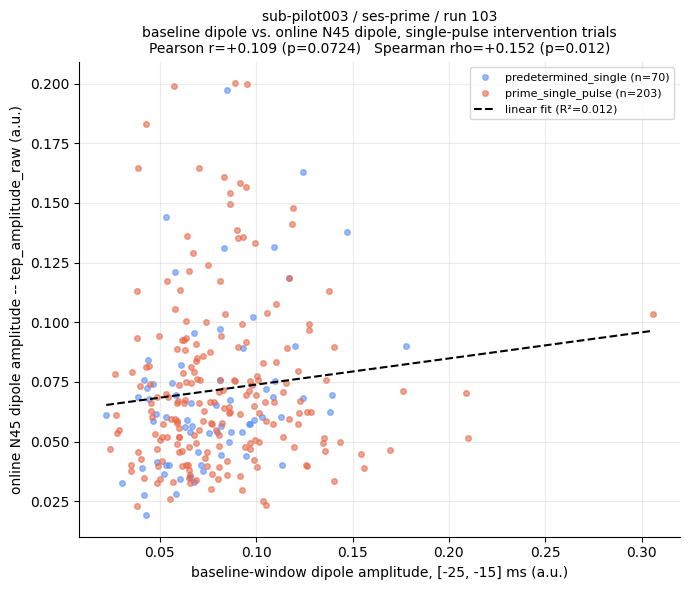

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
colors = {"predetermined_single": COLOR_PREDETERMINED, "prime_single_pulse": COLOR_PRIME_SINGLE}
for cond, d in results.groupby("condition"):
    ax.scatter(d.baseline_dipole_amplitude, d.tep_amplitude_raw, s=16, alpha=0.6,
               color=colors.get(cond, "grey"), label=f"{cond} (n={len(d)})")

xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, lin.slope * xs + lin.intercept, color="black", lw=1.5, ls="--",
        label=f"linear fit (R\u00b2={lin.rvalue**2:.3f})")

ax.set_xlabel(f"baseline-window dipole amplitude, [{BASELINE_TMIN*1000:.0f}, {BASELINE_TMAX*1000:.0f}] ms (a.u.)")
ax.set_ylabel("online N45 dipole amplitude -- tep_amplitude_raw (a.u.)")
ax.set_title(f"sub-{SUBJECT_ID} / {SESSION_ID} / run {RUN_ID}\n"
             f"baseline dipole vs. online N45 dipole, single-pulse intervention trials\n"
             f"Pearson r={r_pearson:+.3f} (p={p_pearson:.3g})   Spearman rho={rho_spearman:+.3f} (p={p_spearman:.3g})",
             fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()

out_png = OUTPUT_DIR / f"{SUBJECT_ID}_baseline_check.png"
fig.savefig(out_png, dpi=150)
print(f"saved plot -> {out_png}")
plt.show()

---
### Notes for reading this on a different session

Everything above is read from files in `SUBJECT_DIR`, or computed from them with a formula grounded
in `prime/decider/` (cited by file and function throughout) — re-point section 1 at a different
`SUBJECT_ID` / `SESSION_ID` / `RUN_ID` and re-run. Needs `calibration_bunble.npy`,
`dipole_fitting_info.npy`, `trials_intervention.csv` and, per trial, `<stem>_post_raw.npy` — the same
files `PRIME_online_performance.ipynb` chapter 2 and `online-TEPs.ipynb` use, see
`claude/online_TEP_replay.md`.